# Análisis Discriminante Lineal (LDA) — Clasificador

**Repositorio:** `autodidact/classification/lda/`

---

## 1. Idea General e Intuición

**LDA** (Linear Discriminant Analysis) es un método **generativo** y **lineal** para clasificación. Su idea central: encontrar la proyección lineal del espacio de features que **maximice la separación entre las medias de las clases** y, simultáneamente, **minimice la varianza dentro de cada clase**.

**Doble rol:**
1. **Clasificador:** Asigna cada punto a la clase con mayor probabilidad posterior.
2. **Reductor de dimensionalidad supervisado:** Proyecta los datos a un subespacio de $K-1$ dimensiones que maximiza la discriminación entre $K$ clases.

**Diferencia con PCA:** PCA maximiza la varianza total (no supervisado). LDA maximiza la separación entre clases (supervisado).

**Supuestos fundamentales:**
- Las features siguen una distribución **normal multivariante** dentro de cada clase.
- Todas las clases comparten la misma **matriz de covarianza** $\Sigma$ (homocedasticidad).

## 2. Fundamento Matemático

### 2.1 Modelo Generativo

LDA asume que los datos de cada clase $C_k$ siguen una gaussiana multivariante con la **misma** covarianza:

$$p(\mathbf{x} \mid y = k) = \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma})$$

### 2.2 Regla de Decisión (Discriminante Lineal)

Por el teorema de Bayes:

$$p(y=k \mid \mathbf{x}) \propto \pi_k \cdot p(\mathbf{x} \mid y=k)$$

Donde $\pi_k = P(y=k)$ es el prior de la clase $k$. Tomando el logaritmo y simplificando (la covarianza compartida cancela el término cuadrático):

$$\delta_k(\mathbf{x}) = \mathbf{x}^\top \boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_k - \frac{1}{2}\boldsymbol{\mu}_k^\top \boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_k + \log \pi_k$$

La clase predicha es:
$$\hat{y} = \underset{k}{\text{argmax}} \; \delta_k(\mathbf{x})$$

$\delta_k(\mathbf{x})$ es **lineal** en $\mathbf{x}$ — de ahí el nombre *lineal*.

### 2.3 Parámetros Estimados del Modelo

$$\hat{\boldsymbol{\mu}}_k = \frac{1}{n_k}\sum_{i: y_i=k} \mathbf{x}_i \qquad \hat{\pi}_k = \frac{n_k}{n}$$

$$\hat{\boldsymbol{\Sigma}} = \frac{1}{n-K}\sum_{k=1}^{K}\sum_{i: y_i=k}(\mathbf{x}_i - \hat{\boldsymbol{\mu}}_k)(\mathbf{x}_i - \hat{\boldsymbol{\mu}}_k)^\top$$

### 2.4 LDA como Reductor de Dimensionalidad

LDA encuentra los **ejes discriminantes** que maximizan el criterio de Fisher:

$$J(\mathbf{w}) = \frac{\mathbf{w}^\top \mathbf{S}_B \mathbf{w}}{\mathbf{w}^\top \mathbf{S}_W \mathbf{w}}$$

Donde:
- $\mathbf{S}_B = \sum_k n_k(\boldsymbol{\mu}_k - \boldsymbol{\mu})(\boldsymbol{\mu}_k - \boldsymbol{\mu})^\top$: **Matriz de dispersión inter-clases** (*between-class scatter*).
- $\mathbf{S}_W = \sum_k \sum_{i: y_i=k}(\mathbf{x}_i - \boldsymbol{\mu}_k)(\mathbf{x}_i - \boldsymbol{\mu}_k)^\top$: **Matriz de dispersión intra-clases** (*within-class scatter*).

Los vectores discriminantes son los autovectores del problema generalizado:

$$\mathbf{S}_B \mathbf{w} = \lambda \mathbf{S}_W \mathbf{w} \quad \Leftrightarrow \quad \mathbf{S}_W^{-1}\mathbf{S}_B \mathbf{w} = \lambda \mathbf{w}$$

El máximo número de ejes discriminantes es $\min(K-1, d)$.

### 2.5 LDA vs QDA

| Aspecto | **LDA** | **QDA** |
|---|---|---|
| Covarianza | **Compartida** $\boldsymbol{\Sigma}$ | **Por clase** $\boldsymbol{\Sigma}_k$ |
| Frontera | **Lineal** | **Cuadrática** |
| Parámetros | $O(d^2 + Kd)$ | $O(Kd^2 + Kd)$ |
| Sesgo | Mayor | Menor |
| Varianza | Menor | Mayor |
| Muestras necesarias | Menos | Más (estimar $K$ covarianzas) |

## 3. ¿Cuándo Usarlo y Cuándo NO?

### ✅ Úsalo cuando:
- Tienes **pocas muestras por clase** y las clases son aproximadamente gaussianas.
- Necesitas **reducción de dimensionalidad supervisada** antes de otro clasificador.
- Las clases tienen **covarianzas similares** (homocedasticidad).
- Como **baseline rápido** y elegante antes de modelos complejos.
- Cuando la **interpretabilidad de los ejes discriminantes** importa.

### ❌ NO lo uses cuando:
- Las distribuciones de clase son **claramente no gaussianas** (bimodal, sesgada).
- Las covarianzas de las clases son **muy distintas** (usar QDA).
- Las features están **fuertemente correlacionadas** de forma no lineal.
- El dataset tiene **muchas más features que muestras** ($d \gg n$) sin regularización.

## 4. Métricas de Evaluación

| Métrica | Fórmula | Cuándo usarla |
|---|---|---|
| **Accuracy** | $\frac{TP+TN}{N}$ | Clases balanceadas |
| **F1-Score** | $\frac{2PR}{P+R}$ | Clases desbalanceadas |
| **ROC-AUC** | Área bajo ROC | Evaluación del ranking |
| **Log-loss** | $-\frac{1}{n}\sum y\log\hat{p}$ | Calibración de probabilidades |
| **Ratio de Fisher** | $\frac{S_B}{S_W}$ | Separabilidad en el espacio discriminante |

## 5. Problemas y Casos Raros

### 5.1 Supuesto de Normalidad Violado
LDA falla si las distribuciones son multimodales o muy asimétricas.
**Diagnóstico:** Q-Q plots, Shapiro-Wilk por clase.
**Solución:** Transformar features (`log`, `Box-Cox`) o usar QDA/modelos no lineales.

### 5.2 Homocedasticidad Violada
Si $\boldsymbol{\Sigma}_k$ varía entre clases, LDA produce fronteras sesgadas.
**Diagnóstico:** Test de Box M.
**Solución:** Usar **QDA** directamente.

### 5.3 Singularidad de $\mathbf{S}_W$ (Problema de Alta Dimensión)
Si $d > n-K$, $\mathbf{S}_W$ es singular y no invertible.
**Solución:** `solver='lsqr'` o `shrinkage='auto'` (LDA regularizado, shrinkage de Ledoit-Wolf).

### 5.4 Clases Desbalanceadas
El prior $\pi_k$ amplifica la clase mayoritaria.
**Solución:** `priors` manual o balancear el dataset.

### 5.5 Máximo $K-1$ Componentes
Con $K$ clases, LDA solo puede proyectar a $K-1$ dimensiones. Para clasificación binaria: **1 solo eje discriminante**.

## 6. Mejora de Resultados

| Parámetro | Efecto |
|---|---|
| `solver='svd'` | Default; no calcula $\mathbf{S}_W$ explícitamente — numéricamente estable |
| `solver='lsqr'` | Más rápido; compatible con `shrinkage` |
| `solver='eigen'` | Calcula autovalores; compatible con `shrinkage` |
| `shrinkage='auto'` | Regularización automática (Ledoit-Wolf) — para $d$ cercano a $n$ |
| `n_components` | Número de ejes discriminantes a conservar (≤ K-1) |
| `priors` | Priors manuales por clase |

**Pipeline recomendado (LDA como feature extractor):**
```
StandardScaler → LDA(n_components=K-1) → [Clasificador final]
```

In [1]:
# =============================================================================
# SETUP
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_iris, load_breast_cancer, load_wine
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay, log_loss
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
SEED = 42
print('✅ Librerías cargadas.')

✅ Librerías cargadas.


---
## 7. LDA como Clasificador — Dataset Wine (3 clases)

In [2]:
# =============================================================================
# CARGA Y EXPLORACIÓN — Wine (13 features químicas, 3 variedades de vino)
# Ideal para LDA: distribuciones aproximadamente gaussianas y 3 clases
# =============================================================================
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Clases: {wine.target_names}')
print(f'Distribución: {pd.Series(y).value_counts().sort_index().to_dict()}')

Train: (142, 13) | Test: (36, 13)
Clases: ['class_0' 'class_1' 'class_2']
Distribución: {0: 59, 1: 71, 2: 48}


In [3]:
# =============================================================================
# MODELO LDA CON PIPELINE
# StandardScaler + LDA — el escalado mejora la estimación de covarianza
# =============================================================================
pipe_lda = Pipeline([
    ('scaler', StandardScaler()),
    ('lda',    LinearDiscriminantAnalysis(solver='svd', n_components=2))
])
pipe_lda.fit(X_train, y_train)
y_pred  = pipe_lda.predict(X_test)
y_proba = pipe_lda.predict_proba(X_test)

print(f'Accuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'Log-loss : {log_loss(y_test, y_proba):.4f}')
print()
print(classification_report(y_test, y_pred, target_names=wine.target_names))

Accuracy : 0.9444
Log-loss : 0.1503

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



In [4]:
# =============================================================================
# PARÁMETROS ESTIMADOS: Medias por clase y covarianza pooled
# =============================================================================
lda_model = pipe_lda.named_steps['lda']
scaler_m   = pipe_lda.named_steps['scaler']

means_df = pd.DataFrame(
    lda_model.means_,
    index=wine.target_names,
    columns=wine.feature_names
)
print('Medias por clase (espacio estandarizado):')
means_df.round(3)

Medias por clase (espacio estandarizado):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
class_0,0.913,-0.252,0.345,-0.736,0.453,0.885,0.997,-0.540,0.481,0.210,0.434,0.771,1.175
class_1,-0.868,-0.388,-0.482,0.238,-0.349,-0.088,0.027,-0.025,0.131,-0.862,0.448,0.235,-0.710
class_2,0.173,0.893,0.297,0.553,-0.037,-0.963,-1.274,0.705,-0.792,1.034,-1.208,-1.306,-0.388


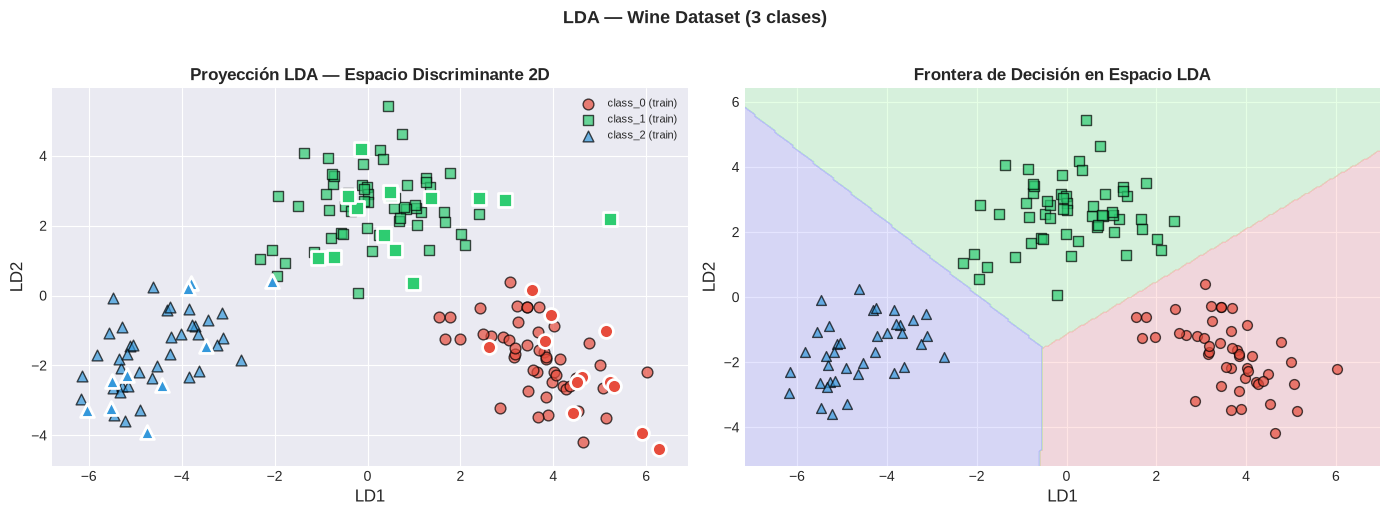

In [5]:
# =============================================================================
# VISUALIZACIÓN 1: Proyección LDA (espacio discriminante 2D)
# Con 3 clases → exactamente 2 ejes discriminantes (K-1 = 2)
# =============================================================================
# Proyectar datos al espacio LDA
scaler_fit   = pipe_lda.named_steps['scaler']
X_train_sc   = scaler_fit.transform(X_train)
X_test_sc    = scaler_fit.transform(X_test)
X_train_lda  = lda_model.transform(X_train_sc)
X_test_lda   = lda_model.transform(X_test_sc)

colors = ['#e74c3c', '#2ecc71', '#3498db']
markers = ['o', 's', '^']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Espacio LDA
for cls, color, marker in zip(range(3), colors, markers):
    mask_tr = y_train == cls
    mask_te = y_test  == cls
    axes[0].scatter(X_train_lda[mask_tr, 0], X_train_lda[mask_tr, 1],
                   color=color, marker=marker, s=60, edgecolors='k', alpha=0.7,
                   label=f'{wine.target_names[cls]} (train)')
    axes[0].scatter(X_test_lda[mask_te, 0], X_test_lda[mask_te, 1],
                   color=color, marker=marker, s=100, edgecolors='white',
                   linewidths=2, alpha=1.0)

axes[0].set_xlabel('LD1', fontsize=12); axes[0].set_ylabel('LD2', fontsize=12)
axes[0].set_title('Proyección LDA — Espacio Discriminante 2D', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=8)

# Frontera de decisión en espacio LDA
h = 0.05
x0r = [X_train_lda[:,0].min()-1, X_train_lda[:,0].max()+1]
x1r = [X_train_lda[:,1].min()-1, X_train_lda[:,1].max()+1]
xx, yy = np.meshgrid(np.arange(x0r[0], x0r[1], h), np.arange(x1r[0], x1r[1], h))

# Clasificar en el espacio LDA (aplicar la regla de decisión sobre los scores)
lda_2d = LinearDiscriminantAnalysis(solver='svd')
lda_2d.fit(X_train_lda, y_train)
Z = lda_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap_bg  = ListedColormap(['#FFAAAA','#AAFFAA','#AAAAFF'])
axes[1].contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bg)
for cls, color, marker in zip(range(3), colors, markers):
    mask_tr = y_train == cls
    axes[1].scatter(X_train_lda[mask_tr, 0], X_train_lda[mask_tr, 1],
                   color=color, marker=marker, s=50, edgecolors='k', alpha=0.7)
axes[1].set_xlabel('LD1', fontsize=12); axes[1].set_ylabel('LD2', fontsize=12)
axes[1].set_title('Frontera de Decisión en Espacio LDA', fontsize=12, fontweight='bold')

plt.suptitle('LDA — Wine Dataset (3 clases)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 8. LDA como Reductor de Dimensionalidad Supervisado

In [6]:
# =============================================================================
# LDA COMO FEATURE EXTRACTOR: comparar clasificadores en espacio original vs LDA
# Wine tiene 13 features → LDA reduce a 2 (K-1=2) sin perder info discriminante
# =============================================================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

classifiers = {
    'KNN (orig.)':         Pipeline([('sc', StandardScaler()),
                                     ('knn', KNeighborsClassifier(5))]),
    'KNN (LDA 2D)':        Pipeline([('sc', StandardScaler()),
                                     ('lda', LinearDiscriminantAnalysis(n_components=2)),
                                     ('knn', KNeighborsClassifier(5))]),
    'LogReg (orig.)':      Pipeline([('sc', StandardScaler()),
                                     ('lr', LogisticRegression(max_iter=500))]),
    'LogReg (LDA 2D)':     Pipeline([('sc', StandardScaler()),
                                     ('lda', LinearDiscriminantAnalysis(n_components=2)),
                                     ('lr', LogisticRegression(max_iter=500))]),
    'LDA solo':            Pipeline([('sc', StandardScaler()),
                                     ('lda', LinearDiscriminantAnalysis())])
}

print(f'{"Clasificador":<22}  {"Accuracy (CV)":>15}  {"Dims usadas":>12}')
print('-' * 55)
for name, clf in classifiers.items():
    sc = cross_val_score(clf, X, y, cv=skf, scoring='accuracy')
    dims = 2 if 'LDA 2D' in name or 'solo' in name else 13
    print(f'{name:<22}  {sc.mean():.4f} ± {sc.std():.4f}  {dims:>12}')

Clasificador              Accuracy (CV)   Dims usadas
-------------------------------------------------------
KNN (orig.)             0.9717 ± 0.0181            13
KNN (LDA 2D)            0.9889 ± 0.0136             2
LogReg (orig.)          0.9833 ± 0.0136            13
LogReg (LDA 2D)         0.9833 ± 0.0222             2
LDA solo                0.9830 ± 0.0139             2


Varianza discriminante explicada:
  LD1: 69.35%
  LD2: 30.65%


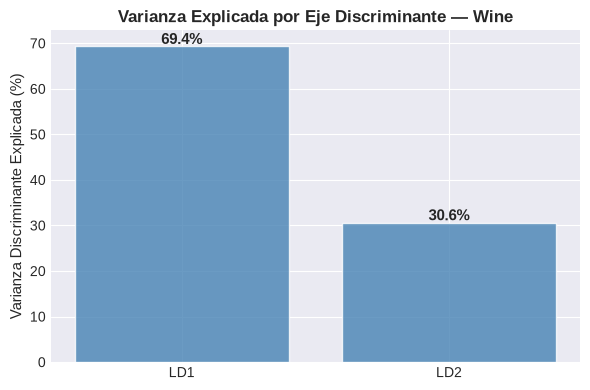

In [7]:
# =============================================================================
# VARIANZA EXPLICADA POR CADA EJE DISCRIMINANTE
# El primer eje discriminante captura la mayor separación entre clases
# =============================================================================
lda_full = LinearDiscriminantAnalysis(solver='svd')
lda_full.fit(StandardScaler().fit_transform(X_train), y_train)

explained_var = lda_full.explained_variance_ratio_
print('Varianza discriminante explicada:')
for i, ev in enumerate(explained_var):
    print(f'  LD{i+1}: {ev*100:.2f}%')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([f'LD{i+1}' for i in range(len(explained_var))],
       explained_var * 100, color='steelblue', alpha=0.8, edgecolor='white')
ax.set_ylabel('Varianza Discriminante Explicada (%)', fontsize=11)
ax.set_title('Varianza Explicada por Eje Discriminante — Wine', fontsize=12, fontweight='bold')
for i, v in enumerate(explained_var):
    ax.text(i, v*100 + 0.5, f'{v*100:.1f}%', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 9. Efecto del Shrinkage (Regularización) — Breast Cancer

In [8]:
# =============================================================================
# BREAST CANCER: LDA con y sin shrinkage de Ledoit-Wolf
# Útil cuando d es grande relativo a n → S_W puede ser mal condicionada
# =============================================================================
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

X_tr_bc, X_te_bc, y_tr_bc, y_te_bc = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=SEED, stratify=y_bc
)

configs = {
    'LDA sin shrinkage':       LinearDiscriminantAnalysis(solver='svd'),
    'LDA shrinkage=auto':      LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'),
    'LDA shrinkage=0.1':       LinearDiscriminantAnalysis(solver='lsqr', shrinkage=0.1),
    'LDA shrinkage=0.5':       LinearDiscriminantAnalysis(solver='lsqr', shrinkage=0.5),
}

print(f'{"Configuración":<28}  {"ROC-AUC (CV)":>14}  {"Accuracy (CV)":>15}')
print('-' * 62)
skf_bc = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, lda_cfg in configs.items():
    pipe_cfg = Pipeline([('sc', StandardScaler()), ('lda', lda_cfg)])
    roc = cross_val_score(pipe_cfg, X_bc, y_bc, cv=skf_bc, scoring='roc_auc')
    acc = cross_val_score(pipe_cfg, X_bc, y_bc, cv=skf_bc, scoring='accuracy')
    print(f'{name:<28}  {roc.mean():.4f} ± {roc.std():.4f}  {acc.mean():.4f} ± {acc.std():.4f}')

Configuración                   ROC-AUC (CV)    Accuracy (CV)
--------------------------------------------------------------
LDA sin shrinkage             0.9929 ± 0.0067  0.9561 ± 0.0200
LDA shrinkage=auto            0.9949 ± 0.0062  0.9596 ± 0.0189
LDA shrinkage=0.1             0.9947 ± 0.0063  0.9561 ± 0.0200
LDA shrinkage=0.5             0.9935 ± 0.0067  0.9543 ± 0.0187


In [ ]:
# =============================================================================
# DISTRIBUCIONES DE LAS PROYECCIONES LDA (BINARY)
# Con 2 clases, LDA produce 1 eje discriminante (K-1=1)
# Las distribuciones bien separadas confirman la capacidad discriminante
# =============================================================================
lda_bc = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
pipe_bc = Pipeline([('sc', StandardScaler()), ('lda', lda_bc)])
pipe_bc.fit(X_tr_bc, y_tr_bc)

X_train_1d = pipe_bc.transform(X_tr_bc).ravel()
X_test_1d  = pipe_bc.transform(X_te_bc).ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribuciones en train
for cls, name, color in zip([0, 1], bc.target_names, ['crimson', 'steelblue']):
    axes[0].hist(X_train_1d[y_tr_bc == cls], bins=25, alpha=0.6,
                color=color, label=name, edgecolor='white')
axes[0].set_xlabel('LD1 (único eje discriminante)', fontsize=11)
axes[0].set_title('Proyecciones LDA por Clase — Train', fontsize=12, fontweight='bold')
axes[0].legend()

# Clasificación en eje 1D
y_pred_bc  = pipe_bc.predict(X_te_bc)
y_proba_bc = pipe_bc.predict_proba(X_te_bc)[:, 1]
ConfusionMatrixDisplay(confusion_matrix(y_te_bc, y_pred_bc),
                       display_labels=bc.target_names).plot(
    ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title(f'Conf. Matrix — LDA Breast Cancer\nROC-AUC={roc_auc_score(y_te_bc, y_proba_bc):.4f}',
                  fontsize=12, fontweight='bold')

plt.suptitle('LDA con Shrinkage — Breast Cancer', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

NotImplementedError: transform not implemented for 'lsqr' solver (use 'svd' or 'eigen').

In [ ]:
# =============================================================================
# VERIFICACIÓN DE SUPUESTOS: Normalidad por clase (Q-Q plots)
# LDA asume normalidad multivariante → verificar con Q-Q sobre las proyecciones LDA
# =============================================================================
import scipy.stats as stats

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for cls, ax in zip(range(3), axes):
    data_cls = X_train_lda[y_train == cls, 0]   # Proyección LD1
    stats.probplot(data_cls, dist='norm', plot=ax)
    ax.set_title(f'Q-Q Plot — {wine.target_names[cls]}\n(Proyección LD1)', fontsize=11, fontweight='bold')
    ax.get_lines()[0].set(color='steelblue', markersize=4)
    ax.get_lines()[1].set(color='crimson')

plt.suptitle('Verificación de Normalidad por Clase (Wine)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# COMPARATIVA FINAL: LDA vs QDA vs LogReg
# =============================================================================
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

models_final = {
    'LDA':       Pipeline([('sc', StandardScaler()),
                            ('m', LinearDiscriminantAnalysis(solver='svd'))]),
    'LDA (reg)': Pipeline([('sc', StandardScaler()),
                            ('m', LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'))]),
    'QDA':       Pipeline([('sc', StandardScaler()),
                            ('m', QuadraticDiscriminantAnalysis())]),
    'LogReg':    Pipeline([('sc', StandardScaler()),
                            ('m', LogisticRegression(C=1.0, max_iter=500))])
}

print(f'{"Modelo":<14}  {"ROC-AUC":>12}  {"Log-loss":>12}  {"Accuracy":>10}')
print('-' * 52)
for name, model in models_final.items():
    roc = cross_val_score(model, X_bc, y_bc, cv=skf_bc, scoring='roc_auc')
    ll  = -cross_val_score(model, X_bc, y_bc, cv=skf_bc, scoring='neg_log_loss')
    acc = cross_val_score(model, X_bc, y_bc, cv=skf_bc, scoring='accuracy')
    print(f'{name:<14}  {roc.mean():.4f}±{roc.std():.3f}  '
          f'{ll.mean():.4f}±{ll.std():.3f}  {acc.mean():.4f}±{acc.std():.3f}')

---
## 10. Resumen y Checklist

| Aspecto | Detalle |
|---|---|
| **Tipo** | Generativo, lineal, probabilístico |
| **Supuestos** | Normalidad multivariante + covarianza compartida |
| **Doble rol** | Clasificador + reductor de dimensión supervisado |
| **Ejes discriminantes** | Máximo $K-1$ (para $K$ clases) |
| **Regularización** | `shrinkage='auto'` (Ledoit-Wolf) |
| **Ventaja** | Muy eficiente, produce proyección interpretable |

### ✅ Checklist LDA:
- [ ] ¿Verifiqué normalidad por clase con Q-Q plots?
- [ ] ¿Las covarianzas de las clases son similares? (si no → QDA)
- [ ] ¿Usé `shrinkage='auto'` si $d$ es cercano a $n$?
- [ ] ¿Visualicé las proyecciones LDA para verificar separabilidad?
- [ ] ¿Aproveché LDA como reductor de dimensión previo a otro clasificador?

---
*Próximo notebook: QDA*